# Computer Vision

## MNIST Digit Classification



Import the libraries used throughout the lab: PyTorch and Torchvision for data and models, scikit-learn for evaluation plots, and the local helper modules. Run this cell before the rest of the notebook.

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchsummary import summary
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import json
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

from PIL import Image

from src import util, helper

Choose the best available compute device: CUDA, Apple Silicon MPS, or CPU. All models and batches later need to use the same device.

In [2]:
# Set computation device
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")

## MNIST dataset

Let's download and load the dataset and display a few random samples from it:

Download (if needed) and load the MNIST training and test splits. `ToTensor` converts grayscale pixels to tensors in the [0, 1] range.

In [3]:
# Download and transform the MNIST dataset
transform = transforms.Compose([
    # Convert images to PyTorch tensors which also scales data from [0,255] to [0,1]
    transforms.ToTensor()
])

# Download training and test datasets
train_dataset = datasets.MNIST(root='./src/data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./src/data', train=False, download=True, transform=transform)


The MNIST dataset object in PyTorch is not a simple tensor or array. It's an iterable dataset that loads samples (image-label pairs) one at a time or in batches. In a later section of this lab, we will define a handy DataLoader to process the data in batches.

Inspect one training example to confirm the dataset returns a single-channel 28×28 image and its integer digit label.

In [4]:
image, label = train_dataset[0]
print(image.size())  # For a tensor: torch.Size([1, 28, 28])
print(label)  # For a label: integer (e.g., 5)

torch.Size([1, 28, 28])
5


Our training set is made up of 28x28 grayscale images of handwritten digits.

Let's visualize what some of these images and their corresponding training labels look like.

Display 36 randomly selected training examples with their labels. The selection changes each time the cell runs.

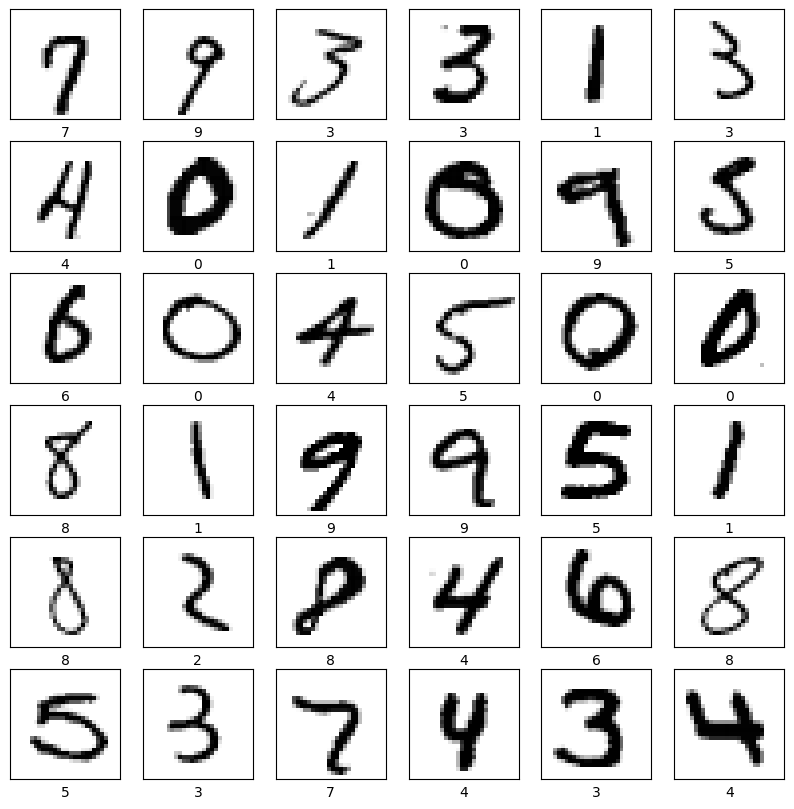

In [5]:
plt.figure(figsize=(10,10))
random_inds = np.random.choice(60000,36)
for i in range(36):
    plt.subplot(6, 6, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    image_ind = random_inds[i]
    image, label = train_dataset[image_ind]
    plt.imshow(image.squeeze(), cmap=plt.cm.binary)
    plt.xlabel(label)


## Neural Network for Handwritten Digit Classification



### Fully connected neural network architecture


Build a sequential baseline classifier: flatten each image, map 784 pixels to 128 hidden units, apply ReLU, then produce 10 class logits.

In [6]:
def build_fc_model():
    fc_model = nn.Sequential(
        # First define a Flatten layer
        nn.Flatten(),

        nn.Linear(28 * 28, 128),

        nn.ReLU(),
    
        nn.Linear(128, 10)
        
    )
    return fc_model

fc_model_sequential = build_fc_model()

### Embracing subclassing in PyTorch

Define the same fully connected architecture as a custom `nn.Module`. This form makes the forward pass explicit and moves the model to the selected device.

In [7]:
# Define the fully connected model
class FullyConnectedModel(nn.Module):
    def __init__(self):
        super(FullyConnectedModel, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)

        # Define the activation function for the first fully connected layer
        self.relu = nn.ReLU()

        # Define the second Linear layer to output the classification probabilities
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

fc_model = FullyConnectedModel().to(device) # send the model to device

### Model Metrics and Training Parameters



Set cross-entropy loss and stochastic gradient descent for the fully connected baseline. The learning rate is an experiment setting.

In [8]:
# Define loss function and optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = optim.SGD(fc_model.parameters(), lr=0.1)

### Train the model



Wrap the training and test splits in DataLoaders. Training batches are shuffled; test batches retain their order.

In [9]:
# Create DataLoaders for batch processing
BATCH_SIZE = 64
trainset_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
testset_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Train the fully connected model with forward pass, loss calculation, backpropagation, and parameter updates. The function currently uses the notebook-level `fc_model` rather than its `model` argument.

In [10]:
def train(model, dataloader, criterion, optimizer, epochs):
    model.train()  # Set the model to training mode
    for epoch in range(epochs):
        total_loss = 0
        correct_pred = 0
        total_pred = 0

        for images, labels in dataloader:
            # Move tensors to GPU so compatible with model
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = fc_model(images)

            # Clear gradients before performing backward pass
            optimizer.zero_grad()
            
            # Calculate loss based on model predictions
            loss = criterion(outputs, labels)

            # Backpropagate and update model parameters
            loss.backward()
            optimizer.step()

            # multiply loss by total nos. of samples in batch
            total_loss += loss.item()*images.size(0)

            # Calculate accuracy
            predicted = torch.argmax(outputs, dim=1)  # Get predicted class
            correct_pred += (predicted == labels).sum().item()  # Count correct predictions
            total_pred += labels.size(0) # Count total predictions

        # Compute metrics
        total_epoch_loss = total_loss / total_pred
        epoch_accuracy = correct_pred / total_pred
        print(f"Epoch {epoch + 1}, Loss: {total_epoch_loss}, Accuracy: {epoch_accuracy:.4f}")


Run the baseline training loop for five epochs and print its per-epoch loss and accuracy.

In [11]:
# Train the model by calling the function appropriately
EPOCHS = 5
train(fc_model, trainset_loader, loss_function, optimizer, EPOCHS)

Epoch 1, Loss: 0.44784272804260256, Accuracy: 0.8789
Epoch 2, Loss: 0.2268543689886729, Accuracy: 0.9357
Epoch 3, Loss: 0.16833896877765656, Accuracy: 0.9522
Epoch 4, Loss: 0.13457006057699522, Accuracy: 0.9614
Epoch 5, Loss: 0.11202610024015108, Accuracy: 0.9687


### Evaluate accuracy on the test dataset


Evaluate a model without gradient updates and report test loss and accuracy. The test loss is accumulated as a tensor; inspect its averaging if changing batch sizes.

In [12]:
def evaluate(model, dataloader, loss_function):
    # Evaluate model performance on the test dataset
    model.eval()
    test_loss = 0
    correct_pred = 0
    total_pred = 0
    # Disable gradient calculations when in inference mode
    with torch.no_grad():
        for images, labels in dataloader:
            # ensure evalaution happens on the GPU
            images, labels = images.to(device), labels.to(device)

            # feed the images into the model and obtain the predictions (forward pass)
            outputs = model(images)

            loss = loss_function(outputs, labels)

            # Calculate test loss
            test_loss += loss_function(outputs, labels)

            # make a prediction and determine whether it is correct!
            # identify the digit with the highest probability prediction for the images in the test dataset.
            predicted = torch.argmax(outputs, dim=1)

            # tally the number of correct predictions
            correct_pred += (predicted == labels).sum().item()

            # tally the total number of predictions
            total_pred += predicted.size(0)

    # Compute average loss and accuracy
    test_loss /= total_pred
    test_acc = correct_pred / total_pred
    return test_loss, test_acc

# call the evaluate function to evaluate the trained model!!
test_loss, test_acc = evaluate(fc_model, testset_loader, loss_function)

print('Test accuracy:', test_acc)

Test accuracy: 0.9676


# Convolutional Neural Network (CNN) for handwritten digit classification

### Define the CNN model



Define a CNN with two convolution/max-pooling stages followed by fully connected layers. The final layer returns 10 logits for cross-entropy classification; the sample forward pass checks the architecture.

In [13]:
### Basic CNN in PyTorch ###

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the first convolutional layer
        self.conv1 = nn.Conv2d(1, 24, kernel_size=3)

        # Define the first max pooling layer
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        # Define the second convolutional layer
        self.conv2 = nn.Conv2d(24, 36, kernel_size=3)

        # Define the second max pooling layer
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(36 * 5 * 5, 128)
        self.relu = nn.ReLU()

        # TODO: Define the Linear layer that outputs the classification
        # logits over class labels. Remember that CrossEntropyLoss operates over logits.
        self.fc2 = nn.Linear(128, 10)


    def forward(self, x):
        # First convolutional and pooling layers
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool1(x)

        # Second convolutional and pooling layers
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool2(x)

        # Fully connected NN
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x

# Instantiate the model
cnn_model = CNN().to(device)

# Initialize the model by passing some data through
image, label = train_dataset[0]
image = image.to(device).unsqueeze(0)  # Add batch dimension → Shape: (1, 1, 28, 28)
output = cnn_model(image)
# Print the model summary
print(cnn_model)

CNN(
  (conv1): Conv2d(1, 24, kernel_size=(3, 3), stride=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(24, 36, kernel_size=(3, 3), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=900, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### Train and test the CNN model



Prepare the CNN experiment: create the model-output directory, read the learning-rate sweep from `hyperparams.json`, and construct batch loaders. The specific hyperparameters are set again for each run below.

In [14]:
# Rebuild the CNN model
cnn_model = CNN().to(device)

models_dir = Path.cwd() / "models"
models_dir.mkdir(exist_ok=True)

with open("hyperparams.json") as f:
    params_list = json.load(f)
    
# Define hyperparams
batch_size = 128
epochs = 7
optimizer = optim.SGD(cnn_model.parameters(), lr=5e-1)

# instantiate the cross entropy loss function
loss_function = nn.CrossEntropyLoss()


# Redefine trainloader with new batch size parameter (tweak as see fit if optimizing)
trainset_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
testset_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Train a fresh CNN for every parameter set in `hyperparams.json`, evaluate it, then save its weights, parameters, metrics, and loss plot under `models/`. `total_loss` is initialized but never incremented, so the printed training loss is always zero; accuracy and test metrics are still calculated.

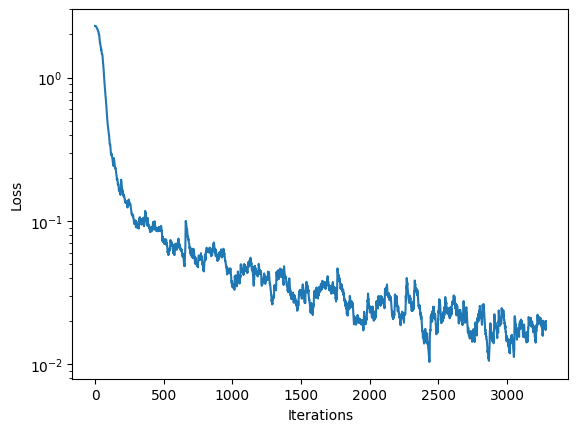

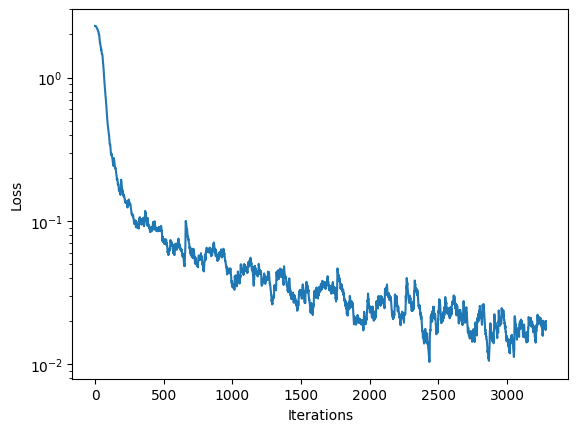

In [15]:
# Training loop!

for params in params_list:
    batch_size = params['batch_size']
    epochs = params['epochs']
    
    run_name = (
    f"lr_{params['lr']:.0e}"
    f"_bs_{batch_size}"
    f"_epochs_{epochs}"
    )
    run_dir = models_dir / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    (run_dir / "params.json").write_text(json.dumps(params, indent=2))

    cnn_model = CNN().to(device)
    cnn_model.train()
    optimizer = optim.SGD(cnn_model.parameters(), lr=params['lr'])
    
    loss_history = util.LossHistory(smoothing_factor=0.95) # to record the evolution of the loss
    plotter = util.PeriodicPlotter(sec=2, xlabel='Iterations', ylabel='Loss', scale='semilogy')

    if hasattr(tqdm, '_instances'): tqdm._instances.clear() # clear if it exists


    for epoch in range(epochs):
        total_loss = 0
        correct_pred = 0
        total_pred = 0

        
        # First grab a batch of training data which our data loader returns as a tensor
        for idx, (images, labels) in enumerate(tqdm(trainset_loader)):
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            # feed the images into the model and obtain the predictions
            logits = cnn_model(images)

            # compute the categorical cross entropy loss using the predicted logits
            loss = loss_function(logits, labels)

            # Get the loss and log it to loss_history record
            loss_value = loss.item()
            loss_history.append(loss_value)
            plotter.plot(loss_history.get())

            # Backpropagation/backward pass
        
            # reset optimizer
            optimizer.zero_grad()
            # compute gradients
            loss.backward()
            # update model parameters
            optimizer.step()

            # Get the prediction and tally metrics
            predicted = torch.argmax(logits, dim=1)
            correct_pred += (predicted == labels).sum().item()
            total_pred += labels.size(0)

        # Compute metrics
        total_epoch_loss = total_loss / total_pred
        epoch_accuracy = correct_pred / total_pred
        print(f"Epoch {epoch + 1}, Loss: {total_epoch_loss}, Accuracy: {epoch_accuracy:.4f}")

    test_loss, test_acc = evaluate(cnn_model, testset_loader, loss_function)
    

    torch.save(
        {
            "model_state_dict": cnn_model.state_dict(),
            "model_path": run_dir,
            "params": params,
            "train_loss": loss.item(),
            "test_loss": test_loss.item(),
            "train_accuracy": epoch_accuracy,
            "test_accuracy": test_acc
        },
        run_dir / "model.pt",
    )

    save_path = run_dir / "loss.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plotter.plot(
        loss_history.get(),
        save_path=save_path
    )


Load saved experiment checkpoints, combine their metrics and parameters into a table, and rank the runs by test accuracy. This expects the training cell to have produced checkpoint files.

In [16]:
results = defaultdict(list)

for run_dir in sorted(models_dir.iterdir()):
    if not run_dir.is_dir():
        print(run_dir, "not found")
        continue

    pt_path = run_dir / "model.pt"
    if not pt_path.exists():
        continue

    checkpoint = torch.load(pt_path, map_location=device, weights_only=False)

    checkpoint |= checkpoint.pop("params")
    for key, value in checkpoint.items():
        results[key].append(value)

    sorted_models = pd.DataFrame(results).sort_values(by="test_accuracy", ascending=False).reset_index(drop=True)


print(sorted_models.drop(columns=["model_state_dict", "model_path"]).to_string())


   train_loss  test_loss  train_accuracy  test_accuracy  batch_size  epochs    lr
0    0.017502   0.000217        0.993400         0.9904         128       7  0.20
1    0.000559   0.000243        0.993950         0.9889         128       7  0.30
2    0.012732   0.000265        0.989400         0.9888         128       7  0.10
3    0.038171   0.000346        0.994117         0.9870         128       7  0.50
4    0.050058   0.000385        0.984417         0.9844         128       7  0.05
5    0.061931   0.000523        0.977833         0.9791         128       7  0.03
6    0.075766   0.000692        0.986750         0.9729         128       7  0.07
7    0.050558   0.000694        0.967667         0.9717         128       7  0.40
8    0.126115   0.001063        0.953717         0.9595         128       7  0.01


### Evaluate the CNN Model



Restore the best-ranked checkpoint and evaluate it on the MNIST test split. The selected run is the first row of the sorted results table.

In [17]:
# Evaluate the CNN model!
cnn_model = CNN().to(device)
cnn_model.load_state_dict(sorted_models.iloc[0]['model_state_dict'], strict=True)
cnn_model.eval()

test_loss, test_acc = evaluate(cnn_model, testset_loader, loss_function)

print('Test accuracy:', test_acc)

Test accuracy: 0.9904


### Make predictions with the CNN model



Run the selected CNN on one test image in evaluation mode. The added batch dimension is required by the model.

In [18]:
test_image, test_label = test_dataset[1]
test_image = test_image.to(device).unsqueeze(0)

# put the model in evaluation (inference) mode
cnn_model.eval()
predictions_test_image = cnn_model(test_image)

Print the model's raw logits for the selected test image. These scores are not probabilities until softmax is applied.

In [19]:
print(predictions_test_image)

tensor([[  3.5060,   8.2857,  19.2469,  -3.1644,  -6.8351, -10.0921,   1.2556,
          -5.1917,   0.9791, -13.7729]], device='mps:0',
       grad_fn=<LinearBackward0>)


Choose the class with the largest logit as the predicted digit and print it.

In [20]:
predictions_value = predictions_test_image.cpu().detach().numpy() #.cpu() to copy tensor to memory first
prediction = np.argmax(predictions_value)
print(prediction)

2


Compare the prediction with the true label and display the test image for a visual check.

Label of this digit is: 2


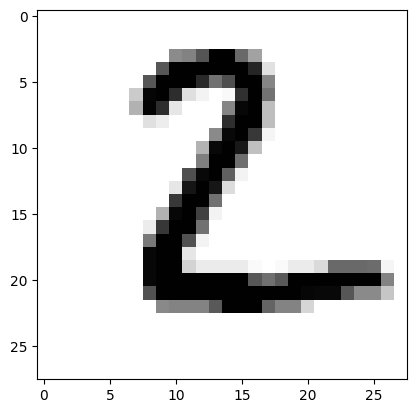

In [21]:
print("Label of this digit is:", test_label)
plt.imshow(test_image[0,0,:,:].cpu(), cmap=plt.cm.binary)


Run inference over the full test set, convert logits to class probabilities, and collect probabilities, labels, and images as NumPy arrays for plotting.

In [22]:
# Initialize variables to store all data
all_predictions = []
all_labels = []
all_images = []

# Process test set in batches
with torch.no_grad():
    for images, labels in testset_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = cnn_model(images)

        # Apply softmax to get probabilities from the predicted logits
        probabilities = torch.nn.functional.softmax(outputs, dim=1)

        # Get predicted classes
        predicted = torch.argmax(probabilities, dim=1)

        all_predictions.append(probabilities)
        all_labels.append(labels)
        all_images.append(images)

all_predictions = torch.cat(all_predictions)  # Shape: (total_samples, num_classes)
all_labels = torch.cat(all_labels)            # Shape: (total_samples,)
all_images = torch.cat(all_images)            # Shape: (total_samples, 1, 28, 28)

# Convert tensors to NumPy for compatibility with plotting functions
predictions = all_predictions.cpu().numpy()  # Shape: (total_samples, num_classes)
test_labels = all_labels.cpu().numpy()       # Shape: (total_samples,)
test_images = all_images.cpu().numpy()       # Shape: (total_samples, 1, 28, 28)

Plot one test example alongside its class-probability bars. Change `image_index` to inspect a different example; it must remain within the test-set range.

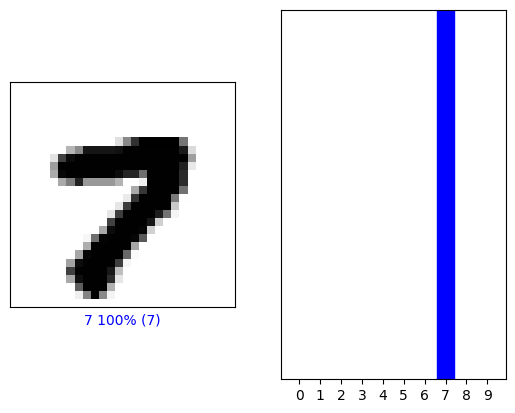

In [23]:
#@title Change the slider to look at the model's predictions! { run: "auto" }

image_index = 79 #@param {type:"slider", min:0, max:100, step:1}
plt.subplot(1,2,1)
helper.plot_image_prediction(image_index, predictions, test_labels, test_images)
plt.subplot(1,2,2)
helper.plot_value_prediction(image_index, predictions, test_labels)


Show a grid of the first 20 test examples, each with its predicted class and class scores. Correct predictions are marked blue and errors red.

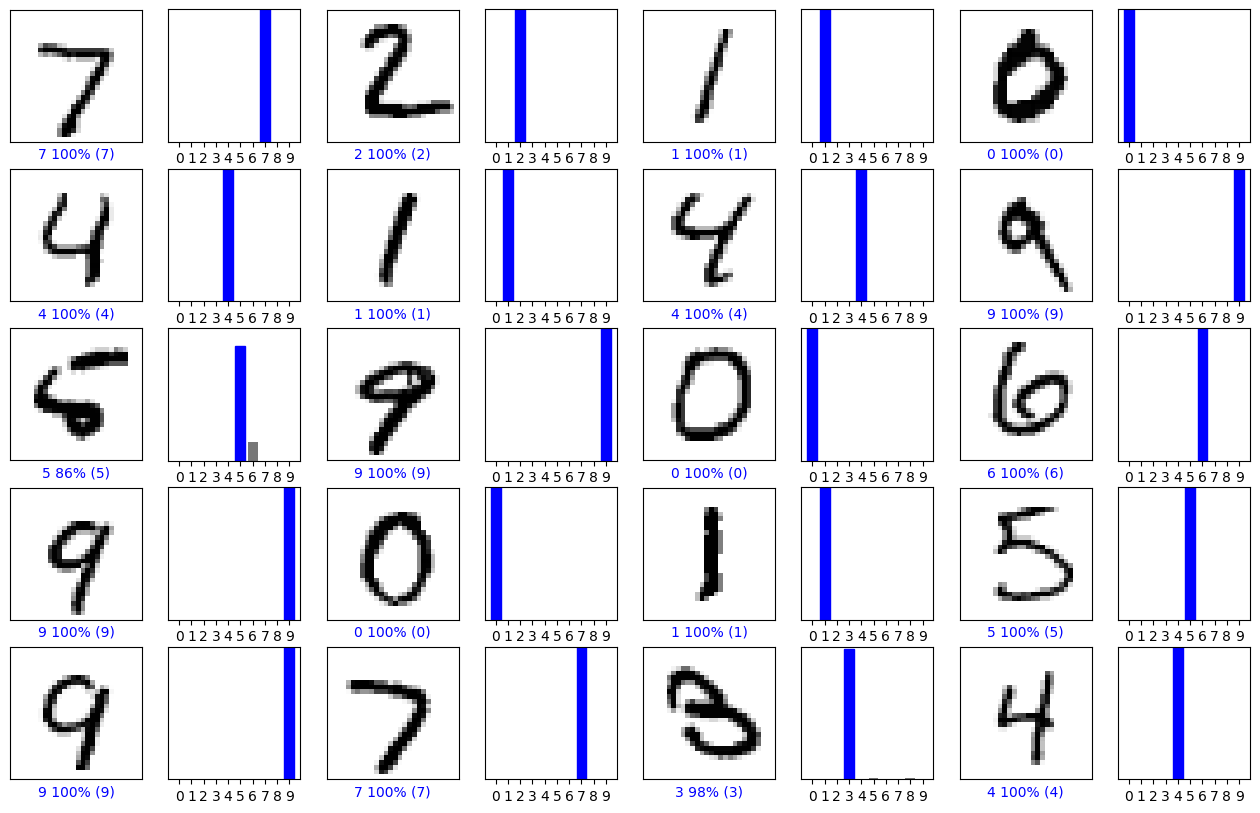

In [24]:
# Plots the first X test images, their predicted label, and the true label
# Color correct predictions in blue, incorrect predictions in red
num_rows = 5
num_cols = 4
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  helper.plot_image_prediction(i, predictions, test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  helper.plot_value_prediction(i, predictions, test_labels)


Load labeled PNG images from `my_test_set`, normalize/crop the handwritten digits, and evaluate every saved model. For each run, save an error summary and image grid; for the best-ranked model, display a confusion matrix. Provide images and labels in the folder before running this cell.

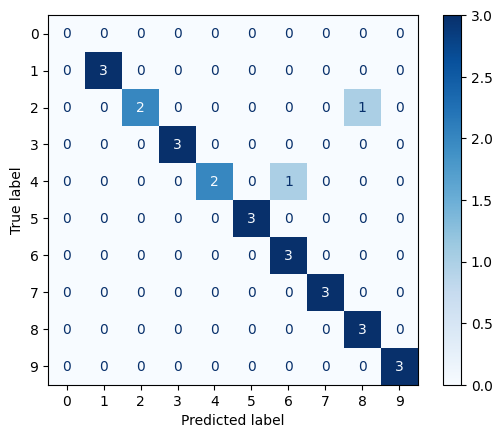

In [ ]:

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x / x.max() if x.max() > 0 else x)
])

my_test_dataset = helper.MyImageDataset("./my_test_set", transform=transform)


my_test_loader = DataLoader(my_test_dataset, batch_size=BATCH_SIZE, shuffle=False)


# Initialize variables to store all data

for idx, row in sorted_models.iterrows():
    all_predictions = []
    all_labels = []
    all_images = []

    cnn_model = CNN().to(device)
    cnn_model.load_state_dict(row['model_state_dict'], strict=True)
    cnn_model.eval()

    # Process test set in batches
    with torch.no_grad():
        for images, labels in my_test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = cnn_model(images)

            # Apply softmax to get probabilities from the predicted logits
            probabilities = torch.nn.functional.softmax(outputs, dim=1)

            # Get predicted classes
            predicted = torch.argmax(probabilities, dim=1)

            all_predictions.append(probabilities)
            all_labels.append(labels)
            all_images.append(images)

    all_predictions = torch.cat(all_predictions)  # Shape: (total_samples, num_classes)
    all_labels = torch.cat(all_labels)            # Shape: (total_samples,)
    all_images = torch.cat(all_images)            # Shape: (total_samples, 1, 28, 28)

    # Convert tensors to NumPy for compatibility with plotting functions
    predictions = all_predictions.cpu().numpy()  # Shape: (total_samples, num_classes)
    test_labels = all_labels.cpu().numpy()       # Shape: (total_samples,)
    test_images = all_images.cpu().numpy()       # Shape: (total_samples, 1, 28, 28)

    errors = {}
    num_rows = 9
    num_cols = 3
    num_images = num_rows*num_cols
    plt.figure(figsize=(2*2*num_cols, 2*num_rows))
    for i in range(num_images):
        plt.subplot(num_rows, 2*num_cols, 2*i+1)
        helper.plot_image_prediction(i, predictions, test_labels, test_images)
        plt.subplot(num_rows, 2*num_cols, 2*i+2)
        
        error = helper.plot_value_prediction(i, predictions, test_labels)
        if error is not None:
            error_idx, prediction = error

            errors[my_test_dataset.get_path(error_idx).name] = (
            int(prediction),
            my_test_dataset.get_label(error_idx)
            )

    fig = plt.gcf()

    plt.savefig(row['model_path'] / f"my_test_{len(errors)}_errors.png", bbox_inches="tight")
    plt.close(fig)

    (row['model_path'] / "errors.json").write_text(json.dumps(errors, indent=2))

    if idx == 0:
        predicted_classes = all_predictions.argmax(dim=1)

        cm = confusion_matrix(
            all_labels.cpu().numpy(),
            predicted_classes.cpu().numpy(),
            labels=range(10)
        )

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=range(10)
        ).plot(cmap="Blues")

        plt.show()
